# 01 — Exploratory Data Analysis: UCI HAR

**Goal:** describe the dataset before modelling: data integrity, class balance, subject split, feature families, per-activity feature distributions, redundancy, and a first look at PCA.

- Data: UCI HAR (561 engineered features per 2.56 s window, 30 subjects, 6 activities). Loaded with `src/har_data.py`.
- Figures are saved to `figures/eda/` as PDF (for the IEEE paper) and PNG.
- The class-balance and subject-split sections describe **train + test**. Everything that could influence modelling choices (distributions, F-scores, correlation, PCA) uses the **training set only**, so the test set stays untouched.
- ✍️ cells are for my own observations and interpretation.

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

sys.path.append("../src")
from har_data import load_har

FIG_DIR = Path("../figures/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Colors: two-series charts use blue/orange; heatmaps use a one-hue ramp;
# correlations use a blue-gray-red diverging map (gray = 0).
BLUE, ORANGE = "#2a78d6", "#eb6834"
LIGHT_GRAY = "#d3d1c7"
INK, INK2 = "#1f1f1e", "#5f5e58"
SEQUENTIAL = LinearSegmentedColormap.from_list("blue_seq", ["#cde2fb", "#2a78d6", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 8, "axes.titlesize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})
COL_W, PAGE_W = 3.5, 7.16  # IEEE single- and double-column widths (inches)

def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", bbox_inches="tight")

In [2]:
d = load_har()
ACT = d.activities                      # {1: 'WALKING', ...}
ORDER = [ACT[i] for i in sorted(ACT)]   # label order 1..6
SHORT = {"WALKING": "Walk", "WALKING_UPSTAIRS": "Upstairs", "WALKING_DOWNSTAIRS": "Downstairs",
         "SITTING": "Sit", "STANDING": "Stand", "LAYING": "Laying"}
DYNAMIC = ORDER[:3]                     # the three walking activities

FEATS = list(d.X_train.columns)
train = d.X_train.assign(activity=d.names(d.y_train), subject=d.subject_train, split="train")
test = d.X_test.assign(activity=d.names(d.y_test), subject=d.subject_test, split="test")
full = pd.concat([train, test], ignore_index=True)
print(f"train {d.X_train.shape} | test {d.X_test.shape}")

train (7352, 561) | test (2947, 561)


## 1. Data integrity

In [3]:
X_all = full[FEATS]
vals = X_all.to_numpy()
pd.Series({
    "windows (train)": len(d.X_train),
    "windows (test)": len(d.X_test),
    "features": len(FEATS),
    "subjects (train / test)": f"{d.subject_train.nunique()} / {d.subject_test.nunique()}",
    "missing values": int(X_all.isna().sum().sum()),
    "non-numeric columns": int((~X_all.dtypes.apply(pd.api.types.is_numeric_dtype)).sum()),
    "constant features": int((X_all.std() == 0).sum()),
    "duplicate rows": int(X_all.duplicated().sum()),
    "identical (copied) feature columns": int(X_all.T.duplicated().sum()),
    "global min / max": f"{vals.min():.3f} / {vals.max():.3f}",
    "values exactly at -1 or +1 (%)": round(100 * np.isin(vals, [-1.0, 1.0]).mean(), 2),
}).to_frame("value")

,value
windows (train),7352
windows (test),2947
features,561
subjects (train / test),21 / 9
missing values,0
non-numeric columns,0
constant features,0
duplicate rows,0
identical (copied) feature columns,21
global min / max,-1.000 / 1.000


✍️ **Observations — integrity:** *(Is any cleaning or imputation needed? What does the [-1, 1] range tell me about how the authors preprocessed the features?)*

## 2. Class balance

In [4]:
counts = pd.crosstab(full["activity"], full["split"]).reindex(ORDER)[["train", "test"]]
pct = counts / counts.sum() * 100
display(counts.join(pct.round(1).add_suffix(" %")))
print("largest / smallest class ratio:", (counts.max() / counts.min()).round(2).to_dict())

split,train,test,train %,test %
activity,,,,
WALKING,1226,496,16.7,16.8
WALKING_UPSTAIRS,1073,471,14.6,16.0
WALKING_DOWNSTAIRS,986,420,13.4,14.3
SITTING,1286,491,17.5,16.7
STANDING,1374,532,18.7,18.1
LAYING,1407,537,19.1,18.2


largest / smallest class ratio: {'train': 1.43, 'test': 1.28}


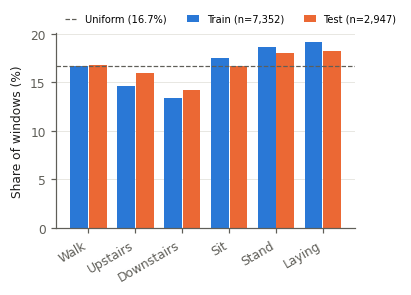

In [5]:
fig, ax = plt.subplots(figsize=(COL_W, 2.3))
x = np.arange(len(ORDER)); w = 0.38
ax.bar(x - w / 2 - 0.01, pct["train"], w, color=BLUE, label=f"Train (n={counts['train'].sum():,})")
ax.bar(x + w / 2 + 0.01, pct["test"], w, color=ORANGE, label=f"Test (n={counts['test'].sum():,})")
ax.axhline(100 / 6, color=INK2, lw=0.8, ls="--", label="Uniform (16.7%)")
ax.set_xticks(x, [SHORT[a] for a in ORDER], rotation=30, ha="right")
ax.set_ylabel("Share of windows (%)")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=6.5, handlelength=1.2)
save(fig, "class_balance"); plt.show()

✍️ **Observations — class balance:** *(How imbalanced is it? Do train and test have the same class mix? Does this call for resampling or class weights, and which metrics should I report?)*

## 3. Subject split

In [6]:
tr_s, te_s = set(d.subject_train), set(d.subject_test)
print("train subjects:", sorted(tr_s))
print("test subjects: ", sorted(te_s))
print("overlap:", sorted(tr_s & te_s) or "none")

per_subj = full.groupby("subject").size()
split_of = full.groupby("subject")["split"].first()
print("\nwindows per subject:")
print(per_subj.describe().round(1).to_string())

train subjects: [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
test subjects:  [2, 4, 9, 10, 12, 13, 18, 20, 24]
overlap: none

windows per subject:
count     30.0
mean     343.3
std       35.7
min      281.0
25%      317.8
50%      342.5
75%      371.0
max      409.0


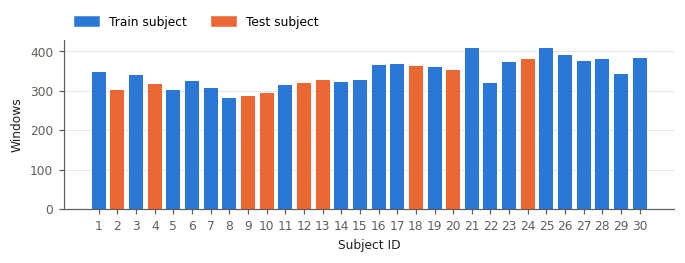

In [7]:
fig, ax = plt.subplots(figsize=(PAGE_W, 2.0))
ax.bar(per_subj.index.astype(str), per_subj.values, width=0.75,
       color=[BLUE if split_of[s] == "train" else ORANGE for s in per_subj.index])
ax.legend([Patch(color=BLUE), Patch(color=ORANGE)], ["Train subject", "Test subject"],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
ax.set_xlabel("Subject ID"); ax.set_ylabel("Windows")
ax.grid(axis="x", visible=False)
save(fig, "windows_per_subject"); plt.show()

smallest subject x activity cell: 36 | largest: 95


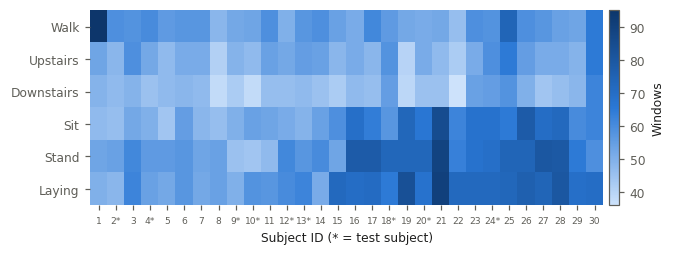

In [8]:
sa = pd.crosstab(full["subject"], full["activity"]).reindex(columns=ORDER)
print("smallest subject x activity cell:", sa.values.min(), "| largest:", sa.values.max())

fig, ax = plt.subplots(figsize=(PAGE_W, 2.3))
im = ax.imshow(sa.T.values, aspect="auto", cmap=SEQUENTIAL)
ax.set_yticks(range(len(ORDER)), [SHORT[a] for a in ORDER])
ax.set_xticks(range(len(sa)), [f"{s}*" if s in te_s else str(s) for s in sa.index], fontsize=6)
ax.set_xlabel("Subject ID (* = test subject)")
ax.grid(False)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
fig.colorbar(im, ax=ax, label="Windows", pad=0.01)
save(fig, "subject_activity_heatmap"); plt.show()

✍️ **Observations — subject split:** *(What does a subject-disjoint test set measure? Does every subject do every activity? What does this mean for how I build cross-validation folds later (Nov 13 task), and why would shuffling individual windows be a problem?)*

## 4. Feature families

Feature names follow `<domain><signal>-<statistic>()[-axis]`: `t` = time domain, `f` = frequency domain (FFT); signals are body/gravity acceleration, gyroscope, their jerk (derivative) and magnitude versions. The 7 `angle(...)` features are angles between mean vectors.

In [9]:
PAT = re.compile(r"([tf])((?:Body)+|Gravity)(Acc|Gyro)(Jerk)?(Mag)?-([A-Za-z]+)")

def family(name):
    if name.startswith("angle("):
        return "angle", "angle", "angle"
    m = PAT.match(name)
    assert m, name
    signal = ("Body" if m[2].startswith("Body") else "Gravity") + m[3] + (m[4] or "") + (m[5] or "")
    return {"t": "time", "f": "frequency"}[m[1]], signal, m[6]

fam = pd.DataFrame([family(f) for f in FEATS], index=FEATS, columns=["domain", "signal", "statistic"])
display(pd.crosstab(fam["signal"], fam["domain"], margins=True))
display(pd.crosstab(fam["statistic"], fam["domain"], margins=True))

domain,angle,frequency,time,All
signal,,,,
BodyAcc,0,79,40,119
BodyAccJerk,0,79,40,119
BodyAccJerkMag,0,13,13,26
BodyAccMag,0,13,13,26
BodyGyro,0,79,40,119
BodyGyroJerk,0,0,40,40
BodyGyroJerkMag,0,13,13,26
BodyGyroMag,0,13,13,26
GravityAcc,0,0,40,40


domain,angle,frequency,time,All
statistic,,,,
angle,7,0,0,7
arCoeff,0,0,80,80
bandsEnergy,0,126,0,126
correlation,0,0,15,15
energy,0,13,20,33
entropy,0,13,20,33
iqr,0,13,20,33
kurtosis,0,13,0,13
mad,0,13,20,33


✍️ **Observations — feature families:** *(How many distinct measurements are really here vs. many statistics of the same few signals? What does that suggest about redundancy?)*

## 5. Feature distributions by activity (train)

Six interpretable features: overall movement intensity (magnitudes) and phone orientation (gravity / angle). Boxes are colored by dynamic (walking) vs. static activities; outliers hidden for readability.

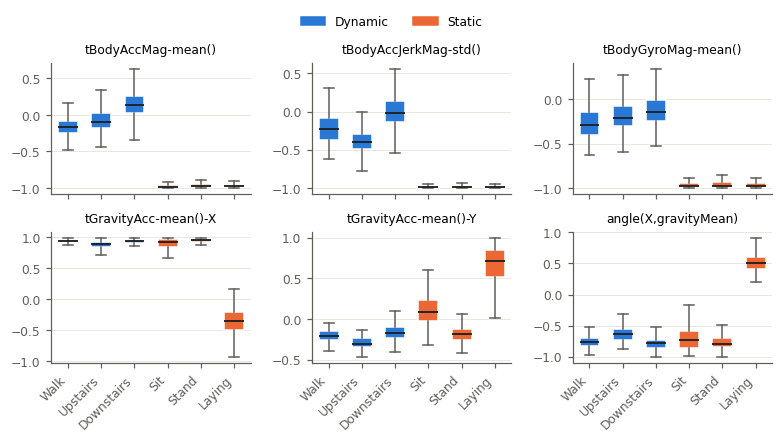

In [10]:
SHOW = ["tBodyAccMag-mean()", "tBodyAccJerkMag-std()", "tBodyGyroMag-mean()",
        "tGravityAcc-mean()-X", "tGravityAcc-mean()-Y", "angle(X,gravityMean)"]

fig, axes = plt.subplots(2, 3, figsize=(PAGE_W, 4.0), sharex=True)
for ax, f in zip(axes.flat, SHOW):
    data = [train.loc[train["activity"] == a, f] for a in ORDER]
    bp = ax.boxplot(data, widths=0.6, patch_artist=True, showfliers=False,
                    medianprops=dict(color=INK, lw=1.2),
                    whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
    for a, box in zip(ORDER, bp["boxes"]):
        box.set(facecolor=BLUE if a in DYNAMIC else ORANGE, edgecolor="white", linewidth=1)
    ax.set_title(f, fontsize=8)
    ax.set_xticks(range(1, 7), [SHORT[a] for a in ORDER], rotation=45, ha="right")
    ax.grid(axis="x", visible=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.legend([Patch(color=BLUE), Patch(color=ORANGE)], ["Dynamic", "Static"],
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
save(fig, "feature_boxplots"); plt.show()

✍️ **Observations — distributions:** *(Which features split dynamic from static? Which separate laying from the others? Which pairs of activities look hardest to tell apart?)*

## 6. Which features separate the activities? (one-way ANOVA F, train)

For each feature, $F = \dfrac{\text{between-class variance}}{\text{within-class variance}}$ — the same F ratio as the regression model-significance table, here with activity as the grouping factor. Large F = class means are far apart relative to the spread inside each class. Computed by hand with NumPy.

In [11]:
def anova_f(X, y):
    X = np.asarray(X, dtype=float); y = np.asarray(y)
    classes = np.unique(y); n, k = len(y), len(classes)
    grand = X.mean(axis=0)
    ssb = sum((y == c).sum() * (X[y == c].mean(axis=0) - grand) ** 2 for c in classes)
    ssw = sum(((X[y == c] - X[y == c].mean(axis=0)) ** 2).sum(axis=0) for c in classes)
    return (ssb / (k - 1)) / (ssw / (n - k))

F_all = pd.Series(anova_f(d.X_train, d.y_train), index=FEATS).sort_values(ascending=False)
print(f"median F over 561 features: {F_all.median():.0f}; features with F < 10: {(F_all < 10).sum()}")
F_all.head(15).round(0).to_frame("F (6 classes)").join(fam)

median F over 561 features: 1463; features with F < 10: 10


,F (6 classes),domain,signal,statistic
fBodyAccJerk-entropy()-X,36918.0,frequency,BodyAccJerk,entropy
tGravityAcc-mean()-X,29363.0,time,GravityAcc,mean
tGravityAcc-min()-X,28175.0,time,GravityAcc,min
fBodyAccJerk-entropy()-Y,28116.0,frequency,BodyAccJerk,entropy
tGravityAcc-max()-X,26687.0,time,GravityAcc,max
tGravityAcc-energy()-X,25982.0,time,GravityAcc,energy
fBodyBodyAccJerkMag-entropy(),23619.0,frequency,BodyAccJerkMag,entropy
tBodyAccJerkMag-entropy(),23437.0,time,BodyAccJerkMag,entropy
fBodyAcc-entropy()-X,23222.0,frequency,BodyAcc,entropy
tBodyAccJerk-entropy()-X,22267.0,time,BodyAccJerk,entropy


In [12]:
ss = train["activity"].isin(["SITTING", "STANDING"])
F_ss = pd.Series(anova_f(train.loc[ss, FEATS], train.loc[ss, "activity"]), index=FEATS).sort_values(ascending=False)
print(f"Sitting vs standing: best F = {F_ss.iloc[0]:.0f}; median F = {F_ss.median():.1f}")
F_ss.head(10).round(1).to_frame("F (sit vs stand)").join(fam)

Sitting vs standing: best F = 2816; median F = 10.1


,F (sit vs stand),domain,signal,statistic
tGravityAcc-max()-Y,2816.0,time,GravityAcc,max
tGravityAcc-mean()-Y,2798.5,time,GravityAcc,mean
"angle(Y,gravityMean)",2690.3,angle,angle,angle
tGravityAcc-min()-Y,2571.4,time,GravityAcc,min
fBodyGyro-meanFreq()-X,821.1,frequency,BodyGyro,meanFreq
"tGravityAcc-correlation()-X,Y",707.8,time,GravityAcc,correlation
tGravityAcc-max()-Z,651.5,time,GravityAcc,max
"angle(Z,gravityMean)",641.1,angle,angle,angle
tGravityAcc-mean()-Z,637.5,time,GravityAcc,mean
tGravityAcc-entropy()-Y,610.4,time,GravityAcc,entropy


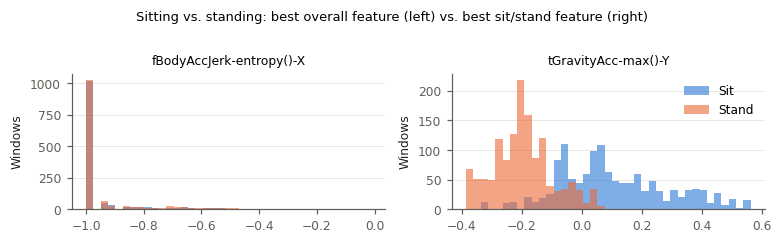

In [13]:
pair = [F_all.index[0], F_ss.index[0]]
fig, axes = plt.subplots(1, 2, figsize=(PAGE_W, 2.1))
for ax, f in zip(axes, pair):
    bins = np.linspace(train.loc[ss, f].min(), train.loc[ss, f].max(), 40)
    for a, c in (("SITTING", BLUE), ("STANDING", ORANGE)):
        ax.hist(train.loc[train["activity"] == a, f], bins=bins, color=c, alpha=0.6, label=SHORT[a])
    ax.set_title(f, fontsize=8); ax.set_ylabel("Windows")
    ax.grid(axis="x", visible=False)
axes[1].legend(loc="upper right")
fig.suptitle("Sitting vs. standing: best overall feature (left) vs. best sit/stand feature (right)", fontsize=8.5, y=1.02)
fig.tight_layout()
save(fig, "sit_vs_stand"); plt.show()

✍️ **Observations — separability:** *(How does the best sit/stand F compare with the 6-class F values? What kind of features separate sit from stand, and is that physically sensible? Prediction for the confusion matrix later?)*

## 7. Feature scale (train)

per-feature means range -0.98 .. 0.83
per-feature stds  range 0.041 .. 0.752


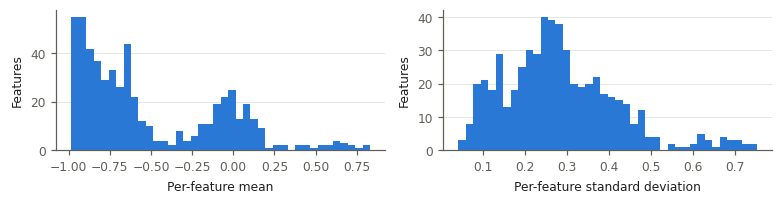

In [14]:
desc = d.X_train.describe().T
print(f"per-feature means range {desc['mean'].min():.2f} .. {desc['mean'].max():.2f}")
print(f"per-feature stds  range {desc['std'].min():.3f} .. {desc['std'].max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(PAGE_W, 1.9))
axes[0].hist(desc["mean"], bins=40, color=BLUE); axes[0].set_xlabel("Per-feature mean")
axes[1].hist(desc["std"], bins=40, color=BLUE); axes[1].set_xlabel("Per-feature standard deviation")
for ax in axes:
    ax.set_ylabel("Features"); ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "feature_scale"); plt.show()

✍️ **Observations — scale:** *(Features are bounded but are they on comparable scales? Should I standardize before gradient descent / PCA / K-means? Why must the mean and std come from the training set only?)*

## 8. Redundancy: feature correlation (train)

In [15]:
C = np.corrcoef(d.X_train.to_numpy(), rowvar=False)
iu = np.triu_indices_from(C, k=1)
r = np.abs(C[iu])
print(f"{len(r):,} feature pairs")
for t in (0.8, 0.9, 0.95, 0.99):
    print(f"  |r| > {t}: {(r > t).sum():>6,} pairs ({100 * (r > t).mean():.1f}%)")
A = np.abs(C) > 0.95; np.fill_diagonal(A, False)
print(f"features with at least one partner at |r| > 0.95: {A.any(axis=1).sum()} of {len(FEATS)}")

top = np.argsort(-r)[:10]
pd.DataFrame({"feature A": [FEATS[i] for i in iu[0][top]], "feature B": [FEATS[j] for j in iu[1][top]],
              "r": C[iu][top].round(4)})

157,080 feature pairs
  |r| > 0.8: 23,058 pairs (14.7%)
  |r| > 0.9:  8,206 pairs (5.2%)
  |r| > 0.95:  2,281 pairs (1.5%)
  |r| > 0.99:    207 pairs (0.1%)
features with at least one partner at |r| > 0.95: 391 of 561


,feature A,feature B,r
0,tBodyAccMag-iqr(),tGravityAccMag-iqr(),1.0
1,fBodyBodyGyroJerkMag-mean(),fBodyBodyGyroJerkMag-sma(),1.0
2,tBodyAccMag-energy(),tGravityAccMag-energy(),1.0
3,tBodyAccMag-entropy(),tGravityAccMag-entropy(),1.0
4,tBodyAccMag-mad(),tGravityAccMag-mad(),1.0
5,tBodyGyroMag-mean(),tBodyGyroMag-sma(),1.0
6,tBodyAccMag-arCoeff()3,tGravityAccMag-arCoeff()3,1.0
7,tBodyAccJerkMag-mean(),tBodyAccJerkMag-sma(),1.0
8,fBodyBodyGyroMag-mean(),fBodyBodyGyroMag-sma(),1.0
9,tBodyAccMag-std(),tGravityAccMag-std(),1.0


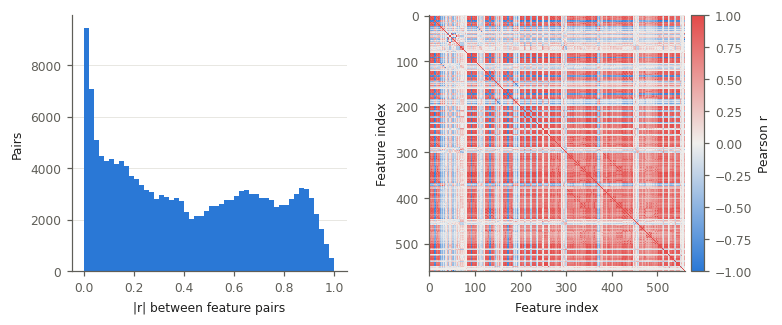

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(PAGE_W, 3.0), gridspec_kw=dict(width_ratios=[1, 1.15]))
axes[0].hist(r, bins=50, color=BLUE)
axes[0].set_xlabel("|r| between feature pairs"); axes[0].set_ylabel("Pairs")
axes[0].grid(axis="x", visible=False)
im = axes[1].imshow(C, cmap=DIVERGING, vmin=-1, vmax=1, interpolation="nearest")
axes[1].set_xlabel("Feature index"); axes[1].set_ylabel("Feature index"); axes[1].grid(False)
fig.colorbar(im, ax=axes[1], label="Pearson r", fraction=0.046, pad=0.02)
fig.tight_layout()
save(fig, "correlation"); plt.show()

✍️ **Observations — redundancy:** *(How redundant is the feature set? What does that imply for logistic regression coefficients (collinearity), for L1 vs. L2, and for PCA?)*

## 9. PCA preview (train)

Exploratory only — the real PCA step (fit on train, applied to test) is the Nov 3–5 task. Here: SVD of the training matrix, both standardized (z-scores) and raw (centered only), to see how many components carry the variance.

In [17]:
mu, sd = d.X_train.mean(), d.X_train.std(ddof=0)
assert (sd > 0).all()
Z = ((d.X_train - mu) / sd).to_numpy()
U, S, Vt = np.linalg.svd(Z, full_matrices=False)
cum_std = np.cumsum(S ** 2) / np.sum(S ** 2)

S_raw = np.linalg.svd(d.X_train.to_numpy() - d.X_train.to_numpy().mean(axis=0), compute_uv=False)
cum_raw = np.cumsum(S_raw ** 2) / np.sum(S_raw ** 2)

pd.DataFrame({t: [int(np.searchsorted(cum_raw, t) + 1), int(np.searchsorted(cum_std, t) + 1)]
              for t in (0.80, 0.90, 0.95, 0.99)},
             index=["centered only", "standardized"]).rename(columns=lambda t: f"{t:.0%} variance")

,80% variance,90% variance,95% variance,99% variance
centered only,10,34,67,155
standardized,26,63,102,179


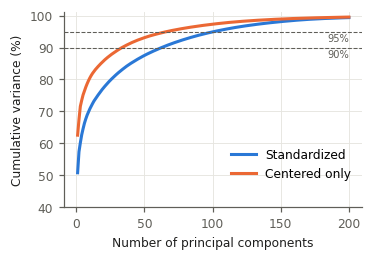

In [18]:
k = np.arange(1, 201)
fig, ax = plt.subplots(figsize=(COL_W, 2.3))
ax.plot(k, cum_std[:200] * 100, color=BLUE, lw=2, label="Standardized")
ax.plot(k, cum_raw[:200] * 100, color=ORANGE, lw=2, label="Centered only")
for t in (90, 95):
    ax.axhline(t, color=INK2, lw=0.7, ls="--")
    ax.text(200, t - 0.6, f"{t}%", ha="right", va="top", fontsize=6.5, color=INK2)
ax.set_xlabel("Number of principal components"); ax.set_ylabel("Cumulative variance (%)")
ax.set_ylim(40, 101); ax.legend(loc="lower right", bbox_to_anchor=(1, 0.08))
save(fig, "pca_cumulative_variance"); plt.show()

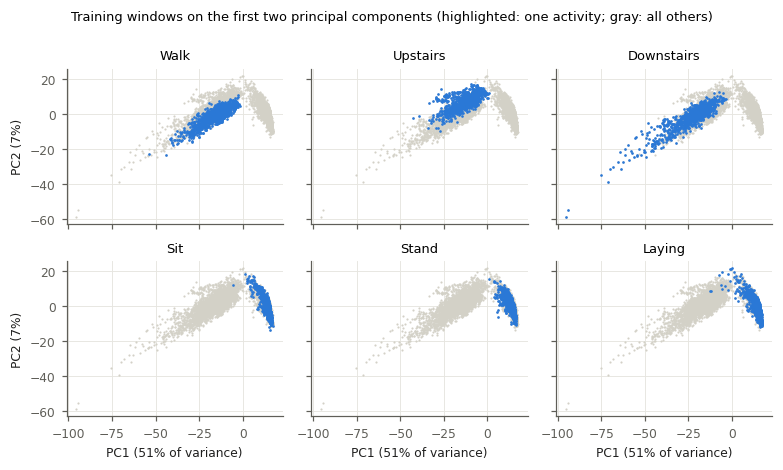

In [19]:
scores = U[:, :2] * S[:2]
evr = S ** 2 / np.sum(S ** 2)
act = train["activity"].to_numpy()

fig, axes = plt.subplots(2, 3, figsize=(PAGE_W, 4.2), sharex=True, sharey=True)
for ax, a in zip(axes.flat, ORDER):
    ax.scatter(scores[:, 0], scores[:, 1], s=2, color=LIGHT_GRAY, linewidths=0, rasterized=True)
    m = act == a
    ax.scatter(scores[m, 0], scores[m, 1], s=3, color=BLUE, linewidths=0, rasterized=True)
    ax.set_title(SHORT[a], fontsize=8.5)
for ax in axes[1]:
    ax.set_xlabel(f"PC1 ({evr[0]:.0%} of variance)")
for ax in axes[:, 0]:
    ax.set_ylabel(f"PC2 ({evr[1]:.0%})")
fig.suptitle("Training windows on the first two principal components (highlighted: one activity; gray: all others)",
             fontsize=8.5, y=1.0)
fig.tight_layout()
save(fig, "pca_2d_by_activity"); plt.show()

✍️ **Observations — PCA:** *(How many components would I keep and why? Which activities overlap in the PC1–PC2 plane, and what does that predict for K-means/FCM against the true labels?)*

## 10. Summary of EDA findings ✍️

*(3–6 bullets in my own words that will become the "Exploratory Analysis" paragraph of the paper. Suggested prompts: integrity / cleaning needed; class balance → metrics; subject-disjoint split → grouped CV; most separable vs. most confusable activities; redundancy → regularization / PCA.)*

-
-
-

**Figures saved** (`figures/eda/`): `class_balance`, `windows_per_subject`, `subject_activity_heatmap`, `feature_boxplots`, `sit_vs_stand`, `feature_scale`, `correlation`, `pca_cumulative_variance`, `pca_2d_by_activity` (each as .pdf and .png).